# Get to Know a Dataset: Florida Seafloor Mapping Initiative (FSMI)

This notebook introduces download functionality for FSMI elevation data through a practical example: **download one specific 10k elevation tile and find the elevation at a given longitude/latitude**. This example shows users how to inspect the tile's metadata, sample the cell containing the point, and visualize the tile with the query location marked.

FSMI is a Florida Department of Environmental Protection initiative to map Florida's seafloor. See the [official FSMI project page](https://www.floridagio.gov/pages/fsmi) for project context.

**Example access:** `s3://florida-seafloor-mapping-initiative-temp/FSMIData/10k/` in `us-west-2`. Anonymous listing and download were verified on October 1, 2026. This temporary bucket is the current access location provided for the application; update it when a permanent location is available. The final Registry URL and dataset license still need provider confirmation. The original template is preserved separately.

### Q: How have you organized your dataset? Help us understand the key prefix structure of your S3 bucket.

The dataset lives under `FSMIData/` in the current temporary bucket. It has two product prefixes, `10k/` and `100k/`. This walkthrough uses `FSMIData/10k/`, which contains 12 directly accessible elevation GeoTIFFs. The selected file is `tile1819_mmblend_clip_epsg6346_r.tif`.

```text
s3://florida-seafloor-mapping-initiative-temp/FSMIData/
|-- 10k/      # 12 elevation GeoTIFFs in the current sample
|   |-- tile1819_mmblend_clip_epsg6346_r.tif
|   |-- tile1820_mmblend_clip_epsg6346_r.tif
|   `-- ...
`-- 100k/     # Companion metadata and world files in the current sample
```

For tile 1819, the raster spans 10,000 by 10,000 meters and contains 10,000 by 10,000 cells at 1-meter horizontal spacing. The `100k/` prefix currently contains companion `.tfw` world files, `.tif.aux.xml` auxiliary metadata, and `.tif.xml` metadata; elevation TIFFs were not present in that prefix when inspected. The runnable example uses only the available 10k elevation products.

An S3 object is addressed by a bucket and an exact key; prefixes group objects but are not local filesystem directories. The listings below reproduce the dataset hierarchy. Empty folder-marker objects may appear with a size of zero bytes.

The template mentioned `License.txt` and `Readme.txt`, but neither was found under `FSMIData/` in the inspected listings. Add the dataset license and documentation links before publication. Use the selected tile's embedded metadata to establish its CRS, elevation units, vertical datum, and NoData handling; obtain acquisition and processing documentation from the provider.

First, import the libraries used throughout the notebook. Install these in the environment used by your Jupyter kernel. Rasterio reads the GeoTIFF, Boto3 retrieves it from S3, and NumPy and Matplotlib support processing and visualization.

In [10]:
# Additional libraries, in requirements.txt format:
# boto3>=1.38
# rasterio>=1.4
# numpy>=1.26
# matplotlib>=3.9

from itertools import islice
from pathlib import Path
from pprint import pprint

import boto3
from botocore import UNSIGNED
from botocore.config import Config
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import transform
from rasterio.windows import Window

The configuration below selects **10k tile 1819** and an example WGS 84 point within its valid coverage: longitude `-82.87913441`, latitude `27.87694227`. This point was chosen near the tile's center to demonstrate a reproducible lookup; it is not a named survey station. Change the tile key and coordinates to query another location, using longitude first.

The selected tile is a numeric single-band elevation GeoTIFF. Its embedded metadata identifies elevation in **meters relative to NAVD88**, with horizontal coordinates in **NAD83(2011) / UTM zone 17N (EPSG:6346)**. The CRS includes the NAVD88 height component (EPSG:5703). Confirm the units and datum again if you select another product.

The bucket supports public, anonymous S3 reads, so no AWS credentials are needed. Access errors are allowed to propagate so failures are visible.

In [11]:
# Current provider-supplied temporary bucket and verified sample tile.
BUCKET = "florida-seafloor-mapping-initiative-temp"
AWS_REGION = "us-west-2"
TILE_KEY = "FSMIData/10k/tile1819_mmblend_clip_epsg6346_r.tif"
LONGITUDE = -82.87913441
LATITUDE = 27.87694227
ELEVATION_UNITS = "meters"
VERTICAL_DATUM = "NAVD88"

# Verified prefix layout for this example.
ROOT_PREFIX = "FSMIData/"
TEN_K_PREFIX = "FSMIData/10k/"
DOWNLOAD_DIR = Path("fsmi_example_data")

if not BUCKET or not AWS_REGION:
    raise ValueError("Set BUCKET and AWS_REGION from the provider's access instructions.")

s3 = boto3.client(
    "s3",
    region_name=AWS_REGION,
    config=Config(
        signature_version=UNSIGNED,
        retries={"mode": "standard", "total_max_attempts": 3},
        connect_timeout=10,
        read_timeout=60,
    ),
)

List the dataset prefix, then inspect its 10k products. The helper uses a paginator so listings remain correct when S3 returns multiple pages. All listings are scoped to `FSMIData/`, and the display is limited to keep the introduction short.

In [12]:
def list_entries(prefix=ROOT_PREFIX, delimiter=None):
    """Yield prefixes and objects from a paginated S3 listing."""
    arguments = {"Bucket": BUCKET, "Prefix": prefix}
    if delimiter is not None:
        arguments["Delimiter"] = delimiter
    pages = s3.get_paginator("list_objects_v2").paginate(**arguments)
    for page in pages:
        for item in page.get("CommonPrefixes", []):
            yield {"prefix": item["Prefix"]}
        for item in page.get("Contents", []):
            yield {"key": item["Key"], "size_bytes": item["Size"]}

print("Dataset prefix (up to 20 entries):")
for entry in islice(list_entries(ROOT_PREFIX, delimiter="/"), 20):
    pprint(entry)

Dataset prefix (up to 20 entries):
{'prefix': 'FSMIData/100k/'}
{'prefix': 'FSMIData/10k/'}
{'key': 'FSMIData/', 'size_bytes': 0}


Look inside the 10k group to see real filenames and object sizes. Tile 1819 is already configured. To choose a different tile, copy its exact elevation GeoTIFF key into the configuration cell and select a point within its coverage. The following listing is an orientation aid, not a spatial tile search.

In [13]:
print("10k objects (up to 20 entries):")
for entry in islice(list_entries(TEN_K_PREFIX), 20):
    pprint(entry)

10k objects (up to 20 entries):
{'key': 'FSMIData/10k/', 'size_bytes': 0}
{'key': 'FSMIData/10k/tile1819_mmblend_clip_epsg6346_r.tif',
 'size_bytes': 382521739}
{'key': 'FSMIData/10k/tile1820_mmblend_clip_epsg6346_r.tif',
 'size_bytes': 383793775}
{'key': 'FSMIData/10k/tile1821_mmblend_clip_epsg6346_r.tif',
 'size_bytes': 388214306}
{'key': 'FSMIData/10k/tile1822_mmblend_clip_epsg6346_r.tif',
 'size_bytes': 378301810}
{'key': 'FSMIData/10k/tile1863_mmblend_clip_epsg6346_r.tif',
 'size_bytes': 366407817}
{'key': 'FSMIData/10k/tile1864_mmblend_clip_epsg6346_r.tif',
 'size_bytes': 390769665}
{'key': 'FSMIData/10k/tile1865_mmblend_clip_epsg6346_r.tif',
 'size_bytes': 357114895}
{'key': 'FSMIData/10k/tile1866_mmblend_clip_epsg6346_r.tif',
 'size_bytes': 367238762}
{'key': 'FSMIData/10k/tile1907_mmblend_clip_epsg6346_r.tif',
 'size_bytes': 355823873}
{'key': 'FSMIData/10k/tile1908_mmblend_clip_epsg6346_r.tif',
 'size_bytes': 398461863}
{'key': 'FSMIData/10k/tile1909_mmblend_clip_epsg6346_r.t

### Q: What data formats are present in your dataset? What kinds of data are stored using these formats? Can you give any advice for how you work with these data formats?

GeoTIFF is a commonly used file format for imagery-derived elevation data. The inspected 10k elevation tiles use **GeoTIFF**. GeoTIFF stores raster cells together with georeferencing information, allowing software to relate each cell to a geographic location. For an elevation product, a numeric band represents the surface elevation relative to a documented vertical datum. Its NoData value or mask identifies cells without usable observations.

GeoTIFF is useful here because georeferencing and raster values can travel together in one widely supported file. Rasterio, GDAL, QGIS, and Esri Enterprise products can read it. Companion overview files can speed up display; they do not replace the full-resolution elevation measurements. The current 100k group contains world files (`.tfw`) and metadata (`.xml`, `.aux.xml`). Additional product formats and their documentation should be confirmed with the provider.

GeoTIFFs can be leveraged in GIS systems to provide volumetric calculations for flood modeling through cross section analysis, for temporal change analysis as part of emergency response and recovery, as a foundational layer for the identification of offshore geologic resources in support of sand mining for beach renourishment projects, and as a shareable digital basemap in support of dynamic natural resource management of coral reef and shipwreck dive sites. 

Amazon S3 provides object access; this notebook downloads one tile for local processing. The same Python workflow can run in an Amazon SageMaker notebook or on Amazon EC2. For larger workflows, select only tiles intersecting your area of interest and use raster windows to limit memory use. Confirm Cloud Optimized GeoTIFF compatibility before relying on efficient remote range reads.

See the [GDAL GeoTIFF documentation](https://gdal.org/en/stable/drivers/raster/gtiff.html) and [Rasterio documentation](https://rasterio.readthedocs.io/en/stable/).

### Q: Can you show us an example of downloading and loading data from your dataset?

Retrieve the selected 10k tile from S3. We inspect its object size before downloading it, then use Boto3's managed file transfer. The tile is saved under `fsmi_example_data/`; rerunning this cell reuses the local file if its size matches the S3 object. This size check is a convenience for this tutorial, not a checksum or a version check; remove the local file to force a new download. This example expects a directly accessible `.tif` or `.tiff`, rather than an archive.

In [14]:
if not TILE_KEY or not TILE_KEY.startswith(TEN_K_PREFIX):
    raise ValueError("Set TILE_KEY to an exact object key within TEN_K_PREFIX.")
if Path(TILE_KEY).suffix.lower() not in {".tif", ".tiff"}:
    raise ValueError("Select the elevation GeoTIFF itself, not an archive or sidecar.")

object_info = s3.head_object(Bucket=BUCKET, Key=TILE_KEY)
print(f"Source: s3://{BUCKET}/{TILE_KEY}")
print(f"Download size: {object_info['ContentLength'] / (1024 ** 2):.1f} MiB")

DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
tile_path = DOWNLOAD_DIR / Path(TILE_KEY).name
partial_path = tile_path.with_suffix(tile_path.suffix + ".part")
if not tile_path.exists() or tile_path.stat().st_size != object_info["ContentLength"]:
    s3.download_file(BUCKET, TILE_KEY, str(partial_path))
    partial_path.replace(tile_path)
    print(f"Downloaded: {tile_path}")
else:
    print(f"Using existing local tile: {tile_path}")

Source: s3://florida-seafloor-mapping-initiative-temp/FSMIData/10k/tile1819_mmblend_clip_epsg6346_r.tif
Download size: 364.8 MiB
Using existing local tile: fsmi_example_data\tile1819_mmblend_clip_epsg6346_r.tif


Open the GeoTIFF and inspect its structure. Raster dimensions describe the number of rows and columns; pixel size and bounds are expressed in the raster CRS. Band units and tags may contain useful metadata, but the companion product documentation remains necessary if the vertical datum or elevation units are absent.

This introductory example expects a single-band numeric elevation product. A single band alone does not prove that a file contains elevation; confirm the product selection in the access instructions.

In [15]:
with rasterio.open(tile_path) as src:
    if src.crs is None:
        raise ValueError("The selected raster has no CRS; obtain its georeferencing before sampling.")
    if src.count != 1:
        raise ValueError("This example expects a single-band elevation GeoTIFF.")
    pprint({
        "driver": src.driver,
        "width_columns": src.width,
        "height_rows": src.height,
        "bands": src.count,
        "data_types": src.dtypes,
        "crs": src.crs.to_string(),
        "pixel_size_in_crs_units": src.res,
        "bounds_in_crs_units": tuple(src.bounds),
        "nodata": src.nodata,
        "band_units": src.units,
        "band_descriptions": src.descriptions,
        "band_scales": src.scales,
        "band_offsets": src.offsets,
        "overview_factors": src.overviews(1),
    })
    print("Dataset tags:")
    pprint(src.tags())
    print("Band 1 tags:")
    pprint(src.tags(1))

{'band_descriptions': (None,),
 'band_offsets': (0.0,),
 'band_scales': (1.0,),
 'band_units': ('metre',),
 'bands': 1,
 'bounds_in_crs_units': (310000.0, 3080000.0, 320000.0, 3090000.0),
 'crs': 'COMPD_CS["NAD83(2011) / UTM zone 17N + NAVD88 '
        'height",PROJCS["NAD83(2011) / UTM zone '
        '17N",GEOGCS["NAD83(2011)",DATUM["NAD83_National_Spatial_Reference_System_2011",SPHEROID["GRS '
        '1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","1116"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","6318"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-81],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","6346"]],VERT_CS["NAVD88 '
        'height",VERT_DATUM["North American Vertical

### Q: What is one question that you have answered using these data? Can you show us how you came to that answer?

**Example question: What elevation does the selected 10k tile report at a given longitude and latitude?**

We transform the point from WGS 84 into the tile's horizontal CRS, locate the raster cell that contains it, and read just that cell at full resolution. We check the row/column bounds and NoData mask, then apply any stored band scale and offset. The result is the containing cell's value, without interpolation. A point outside the tile or in a NoData cell has no elevation answer from this tile.

The horizontal transform does not convert the elevation's vertical datum. Negative elevation means below the product's vertical zero; it is not automatically water depth relative to the water surface at a particular time. To interpret the answer, report the units and vertical datum from the product metadata alongside the value, tile key, and input coordinates.

See Rasterio's [coordinate transforms](https://rasterio.readthedocs.io/en/stable/topics/transforms.html) and [NoData masks](https://rasterio.readthedocs.io/en/stable/topics/masks.html). The code below produces the answer for the configured tile and example point.

By knowling the exact elevation of this point, a user can determine if this is a suitable location for a coral nursery in support of reestablishing a threatened coral species. 

**Verified example answer:** At longitude `-82.87913441`, latitude `27.87694227`, tile 1819 reports **-5.373 meters relative to NAVD88** (rounded to three decimal places). This is cell row 5010, column 5010 using zero-based indices. The displayed precision is formatting, not a claim of millimeter measurement accuracy.


In [16]:
def elevation_at_point(path, longitude, latitude):
    """Read the containing cell; return its scaled value or a missing-data status."""
    if longitude is None or latitude is None:
        raise ValueError("Set LONGITUDE and LATITUDE to the example point.")
    if not (np.isfinite(longitude) and np.isfinite(latitude)):
        raise ValueError("Coordinates must be finite numbers.")
    if not (-180 <= longitude <= 180 and -90 <= latitude <= 90):
        raise ValueError("Expected WGS 84 longitude and latitude in degrees.")

    with rasterio.open(path) as src:
        if src.crs is None or src.count != 1:
            raise ValueError("Expected a georeferenced single-band elevation raster.")
        xs, ys = transform("EPSG:4326", src.crs, [longitude], [latitude])
        x, y = xs[0], ys[0]
        if not (np.isfinite(x) and np.isfinite(y)):
            raise ValueError("The point cannot be transformed into this raster's CRS.")
        row, col = src.index(x, y)
        result = {
            "longitude": float(longitude), "latitude": float(latitude),
            "raster_crs": src.crs.to_string(), "raster_x": x, "raster_y": y,
            "row": int(row), "column": int(col), "elevation": None,
        }
        if not (0 <= row < src.height and 0 <= col < src.width):
            return {**result, "status": "outside_tile"}

        pixel = src.read(1, window=Window(col, row, 1, 1), masked=True)
        if np.ma.is_masked(pixel[0, 0]) or not np.isfinite(pixel[0, 0]):
            return {**result, "status": "nodata"}
        elevation = float(pixel[0, 0]) * src.scales[0] + src.offsets[0]
        if not np.isfinite(elevation):
            return {**result, "status": "nodata"}
        center_x, center_y = src.xy(row, col)
        return {
            **result, "status": "ok", "elevation": elevation,
            "cell_center_x": center_x, "cell_center_y": center_y,
        }

result = elevation_at_point(tile_path, LONGITUDE, LATITUDE)
pprint({
    "source": f"s3://{BUCKET}/{TILE_KEY}",
    **result,
    "elevation_units": ELEVATION_UNITS or "Unconfirmed; consult product metadata",
    "vertical_datum": VERTICAL_DATUM or "Unconfirmed; consult product metadata",
})
if result["status"] == "ok":
    print(f"Containing cell elevation: {result['elevation']:.3f} "
          f"{ELEVATION_UNITS or '(units unconfirmed)'}")
else:
    print(f"No elevation returned: {result['status']}. Check tile selection and coverage.")

{'cell_center_x': np.float64(315010.5),
 'cell_center_y': np.float64(3084989.5),
 'column': 5010,
 'elevation': -5.372661590576172,
 'elevation_units': 'metres',
 'latitude': 27.87694227,
 'longitude': -82.87913441,
 'raster_crs': 'COMPD_CS["NAD83(2011) / UTM zone 17N + NAVD88 '
               'height",PROJCS["NAD83(2011) / UTM zone '
               '17N",GEOGCS["NAD83(2011)",DATUM["NAD83_National_Spatial_Reference_System_2011",SPHEROID["GRS '
               '1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","1116"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","6318"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-81],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","6346"]],VERT_CS["NAVD8

### Q: A picture is worth a thousand words. Show us a visual (or several!) from your dataset that either illustrates something informative about your dataset, or that you think might excite someone to dig in further.

This data can be used to highlight features on the seafloor, such as the coral formations in the image below.

<img src="https://fgio.maps.arcgis.com/sharing/rest/content/items/b70cabb09573443a89252ed7d366d0d4/data" alt="An image of a seafloor elevation map in an area with coral formations" width="1000" height="750">

The data can also be used to visualize an area around a point of interest. The following example uses the same coordinates where the seafloor elevation was identified above.

Plot the selected tile and mark the queried cell. A downsampled preview limits the display array to at most 1,200 cells on its longest side. We use nearest-neighbor resampling, mask missing and nonfinite values, and apply the same band scale and offset used in the point lookup. The point answer above uses the original resolution, independently of the preview.

The axes show projected easting and northing in meters in the tile's horizontal CRS. The queried location is transformed into the same CRS. This map display expects a north-up raster, as verified for tile 1819. Blank areas indicate masked preview cells; this preview does not quantify full-resolution data coverage.

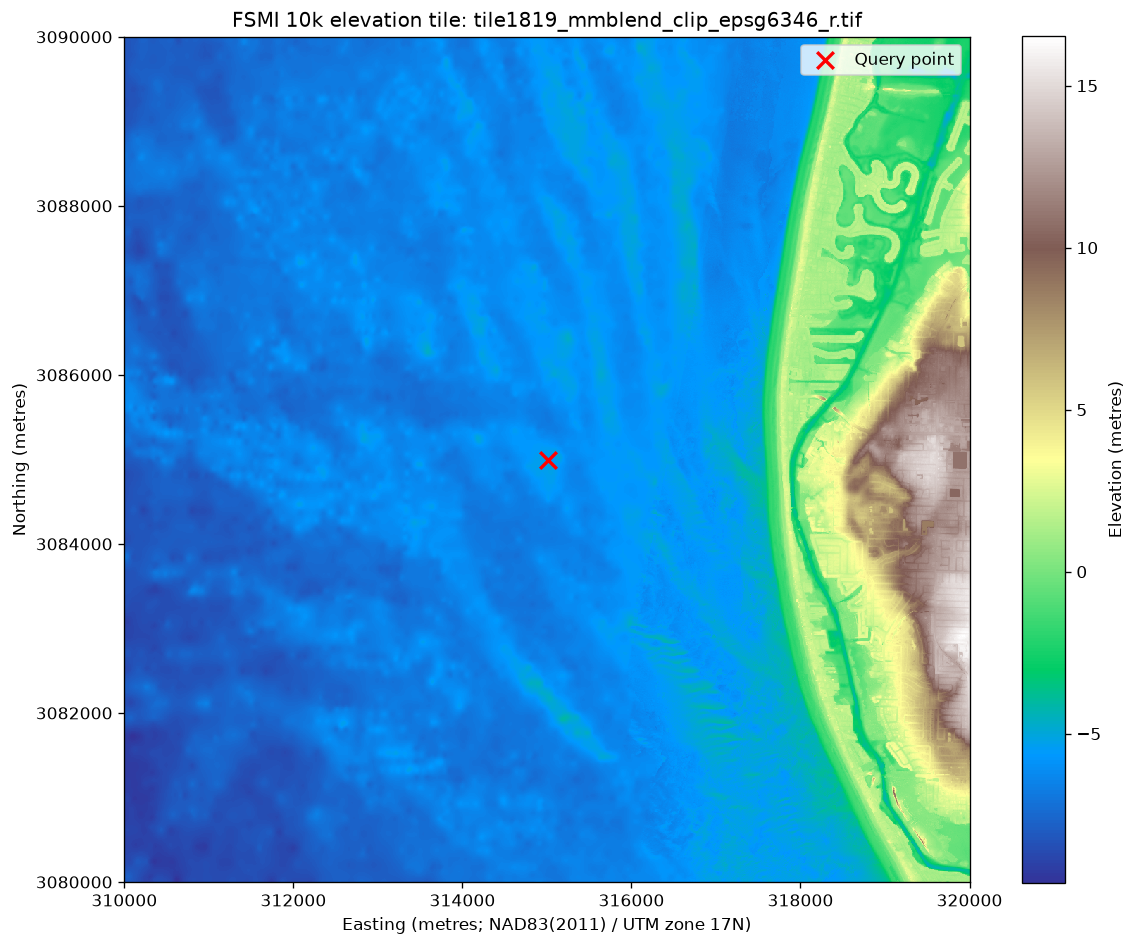

In [17]:
with rasterio.open(tile_path) as src:
    ratio = min(1.0, 1200 / max(src.height, src.width))
    preview_height = max(1, round(src.height * ratio))
    preview_width = max(1, round(src.width * ratio))
    preview = src.read(
        1, out_shape=(preview_height, preview_width),
        masked=True, resampling=Resampling.nearest,
    ).astype("float64")
    preview = np.ma.masked_invalid(preview * src.scales[0] + src.offsets[0])
    if src.transform.b != 0 or src.transform.d != 0 or src.transform.a <= 0 or src.transform.e >= 0:
        raise ValueError("This map display expects a north-up raster.")
    left, bottom, right, top = src.bounds

fig, ax = plt.subplots(figsize=(10, 8), dpi=120)
ax.set_facecolor("#eeeeee")
if preview.count():
    image = ax.imshow(
        preview, cmap="terrain", origin="upper",
        extent=(left, right, bottom, top), interpolation="nearest",
    )
    fig.colorbar(image, ax=ax, label=f"Elevation ({ELEVATION_UNITS or 'units unconfirmed'})")
else:
    ax.set_xlim(left, right)
    ax.set_ylim(bottom, top)
    ax.text(0.5, 0.5, "No valid values in the preview", transform=ax.transAxes, ha="center")

if result["status"] != "outside_tile":
    ax.scatter(result["raster_x"], result["raster_y"],
               marker="x", s=100, color="red", linewidths=2, label="Query point")
    ax.legend(loc="upper right")
ax.set_title(f"FSMI 10k elevation tile: {tile_path.name}")
ax.set_xlabel("Easting (meters; NAD83(2011) / UTM zone 17N)")
ax.set_ylabel("Northing (meters)")
ax.ticklabel_format(style="plain", useOffset=False)
fig.tight_layout()
plt.show()

The last visual shows the elevation distribution of the preview's valid samples. This provides context for the selected point and the tile's terrain variation. Statistics here describe the downsampled preview, not all original cells, and are not area-weighted or survey uncertainty estimates.

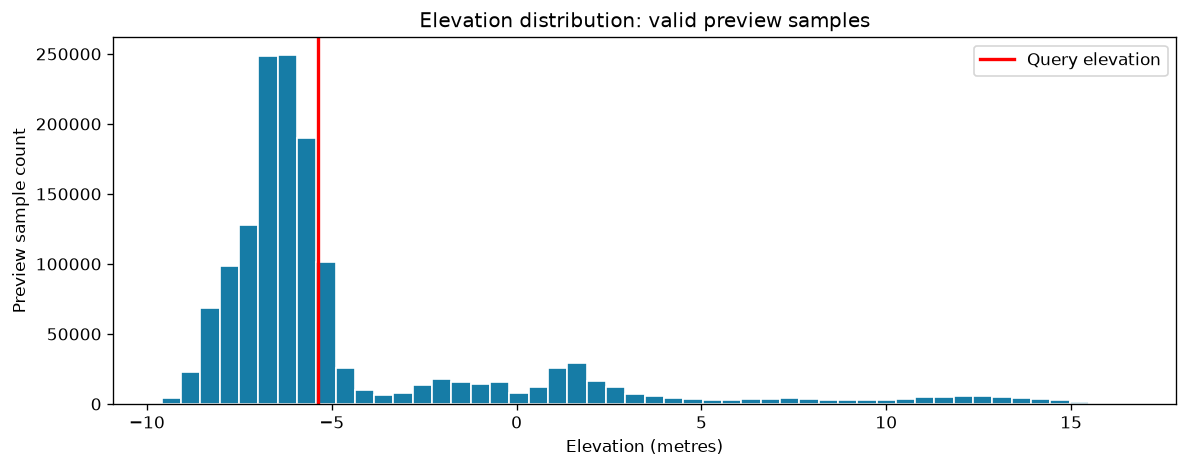

{'preview_maximum': 16.5319766998291,
 'preview_median': -6.155368804931641,
 'preview_minimum': -9.602280616760254}


In [18]:
preview_values = preview.compressed()
if preview_values.size:
    fig, ax = plt.subplots(figsize=(10, 4), dpi=120)
    ax.hist(preview_values, bins=50, color="#167ca6", edgecolor="white")
    if result["status"] == "ok":
        ax.axvline(result["elevation"], color="red", linewidth=2, label="Query elevation")
        ax.legend()
    ax.set_title("Elevation distribution: valid preview samples")
    ax.set_xlabel(f"Elevation ({ELEVATION_UNITS or 'units unconfirmed'})")
    ax.set_ylabel("Preview sample count")
    fig.tight_layout()
    plt.show()
    pprint({"preview_minimum": float(preview_values.min()),
            "preview_median": float(np.median(preview_values)),
            "preview_maximum": float(preview_values.max())})
else:
    print("No valid preview samples to summarize.")

### Q: What is one unanswered question that you think could be answered using these data? Do you have any recommendations or advice for someone wanting to answer this question?

**Where does the elevation data support development of resilient infrastructure in the nearshore areas off Cedar Key, Florida?**

By analyzing FSMI DEM data within a mile around Cedar Key, Florida, users can identify areas that would benefit from resilient solutions like living shorelines. Having this elevation data incorporated with existing flood, vessel debris, and damage data will help managers pinpoint locations that will provide the greatest positive impact.

### Publication details and extending the example

The example uses the provider's current temporary bucket. Before submission, confirm the permanent bucket location and final Registry of Open Data landing page URL, and supply the dataset license, acquisition dates, processing/accuracy documentation, and product documentation links. Elevation units and the vertical datum for tile 1819 were verified from its embedded metadata. Do not assume another product has the same metadata without checking it.

To query a different location, replace `TILE_KEY`, `LONGITUDE`, and `LATITUDE`, inspect the new tile's metadata, and update the elevation units and vertical datum as needed. The lookup returns `outside_tile` or `nodata` rather than a fabricated elevation when the selected tile cannot answer the query.

Execution outputs are cleared in the submission notebook, as requested by the supplied template. Run the cells from top to bottom to reproduce the listings, elevation answer, and visualizations.